<a href="https://colab.research.google.com/github/andres-merino/AprendizajeAutomaticoInicial-05-N0105/blob/main/2-Ejercicios/03-Agrupamiento-Jerarquico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Facultad de Ciencias Exactas, Naturales y Ambientales</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Aprendizaje Automático Inicial &bull; Agrupamiento Jerarquico
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Andrés Merino &bull; 2025-04
            </font></p>
        </td>  
    </tr>
</table>

---
## <font color='264CC7'> Introducción </font>

A lo largo de este taller, aplicaremos el algoritmo de agrupamiento jerárquico a un conjunto de datos.

Los paquetes necesarios son:

In [3]:
# Paquetes necesarios para agrupamiento jerárquico y visualización
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

---
## <font color='264CC7'> Preprocesamiento de datos </font>

Usa el conjunto Pokémon del notebook de agrupamiento jerárquico o un conjunto de datos numéricos que hayas preparado. Si eliges Pokémon, carga [Pokemon.csv](https://raw.githubusercontent.com/andres-merino/AprendizajeAutomaticoInicial-05-N0105/refs/heads/main/2-Notebooks/datos/Pokemon.csv) en Colab y usa las mismas columnas numéricas del notebook de clase; documenta las variables elegidas.

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Carga el conjunto de datos y procésalos:
<ul>
  <li>Muestra algunos datos.</li>
  <li>Muestra una descripción de los datos.</li>
  <li>Escala los datos si es necesario.</li>
</ul>
</div>

In [4]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

# URL del conjunto de datos en GitHub
url = 'https://raw.githubusercontent.com/FJ039/Aprendizaje-Automatico/refs/heads/main/siniestros_transito_2019_limpio.csv'

# Cargar los datos especificando el separador de punto y coma
df = pd.read_csv(url, sep=';')

# Mostrar las primeras filas del conjunto de datos
print("--- Primeras filas del conjunto de datos ---")
display(df.head())

# Seleccionar variables numéricas para el agrupamiento
features = ['NUM_FALLECIDO', 'NUM_LESIONADO', 'TOTAL_VICTIMAS']
X = df[features]

# Escalar los datos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\n--- Datos seleccionados y escalados (primeras 5 filas) ---")
print(pd.DataFrame(X_scaled, columns=features).head())

--- Primeras filas del conjunto de datos ---


,MES,DIA,HORA,PROVINCIA,CANTON,ZONA,NUM_FALLECIDO,NUM_LESIONADO,TOTAL_VICTIMAS,CLASE,CAUSA
0,ENERO,MARTES,11:00 A 11:59,IMBABURA,OTAVALO,URBANA,0,0,0,PÉRDIDA DE PISTA,IMPERICIA E IMPRUDENCIA DEL CONDUCTOR
1,ENERO,MARTES,23:00 A 23:59,IMBABURA,IBARRA,RURAL,0,0,0,OTROS,OTRAS CAUSAS
2,ENERO,MARTES,12:00 A 12:59,TUNGURAHUA,AMBATO,URBANA,0,3,3,CHOQUES,NO RESPETA LAS SEÑALES DE TRÁNSITO
3,ENERO,MARTES,07:00 A 07:59,TUNGURAHUA,AMBATO,RURAL,0,1,1,ATROPELLOS,EMBRIAGUEZ O DROGA
4,ENERO,MARTES,04:00 A 04:59,PICHINCHA,DISTRITO METROPOLITANO DE QUITO,URBANA,0,0,0,ESTRELLAMIENTOS,EXCESO VELOCIDAD



--- Datos seleccionados y escalados (primeras 5 filas) ---
   NUM_FALLECIDO  NUM_LESIONADO  TOTAL_VICTIMAS
0      -0.277195      -0.741415       -0.785987
1      -0.277195      -0.741415       -0.785987
2      -0.277195       1.961120        1.792080
3      -0.277195       0.159430        0.073369
4      -0.277195      -0.741415       -0.785987


---
## <font color='264CC7'> Dendograma </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Genera el dendograma de los datos.
<ul>
  <li>Usa diferentes métricas y funciones de enlace.</li>
  <li>Toma una distancia de corte.</li>
  <li>De manera intutiva, ¿por qué tomaste la métrica y la distancia de corte?</li>
</ul>
</div>

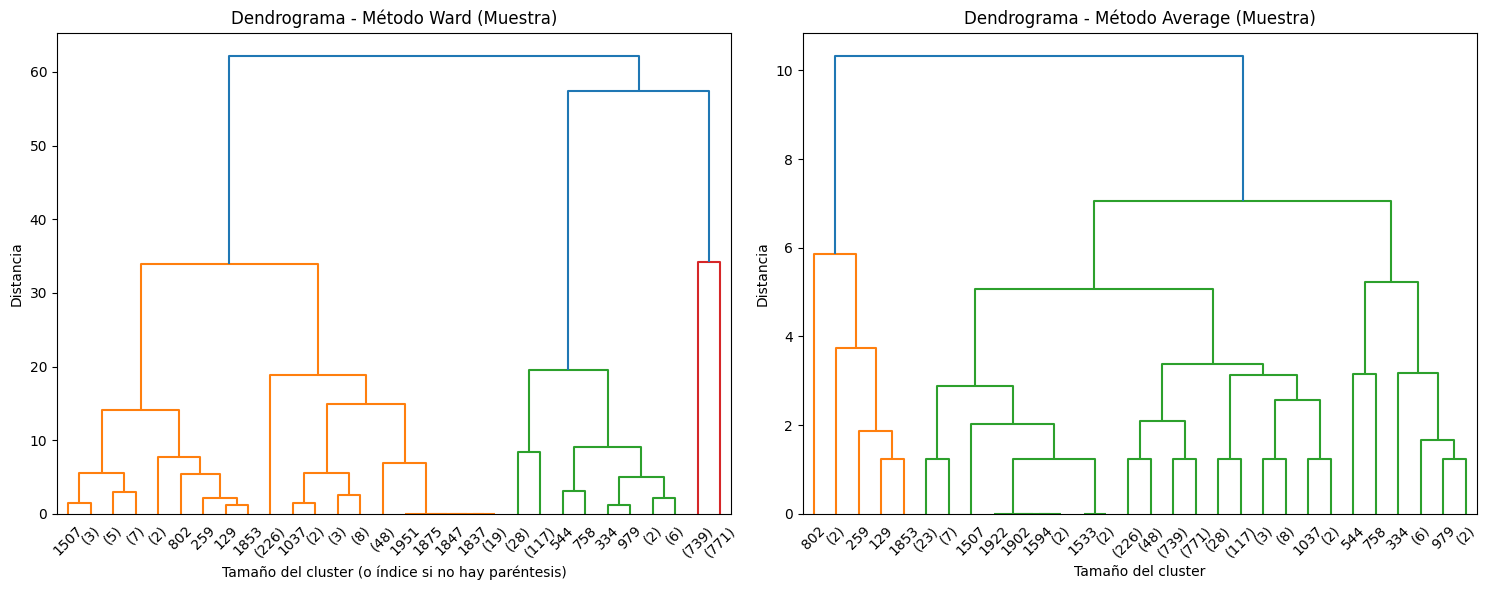

In [5]:
# Para evitar problemas de memoria con más de 23,000 registros, tomamos una muestra
np.random.seed(42)
sample_indices = np.random.choice(X_scaled.shape[0], size=2000, replace=False)
X_sample = X_scaled[sample_indices]

# Calcular los enlaces utilizando diferentes métodos
Z_ward = linkage(X_sample, method='ward', metric='euclidean')
Z_average = linkage(X_sample, method='average', metric='euclidean')

# Graficar los dendrogramas para comparar
plt.figure(figsize=(15, 6))

plt.subplot(1, 2, 1)
dendrogram(Z_ward, truncate_mode='lastp', p=30, show_leaf_counts=True)
plt.title('Dendrograma - Método Ward (Muestra)')
plt.xlabel('Tamaño del cluster (o índice si no hay paréntesis)')
plt.ylabel('Distancia')

plt.subplot(1, 2, 2)
dendrogram(Z_average, truncate_mode='lastp', p=30, show_leaf_counts=True)
plt.title('Dendrograma - Método Average (Muestra)')
plt.xlabel('Tamaño del cluster')
plt.ylabel('Distancia')

plt.tight_layout()
plt.show()

---
## <font color='264CC7'> Asignación de grupos y análisis </font>


<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza un análisis de los grupos obtenidos.
<ul>
  <li>Asigna los grupos.</li>
  <li>Revisa la media de cada grupo.</li>
  <li>Revisa el mínimo y máximo de cada grupo.</li>
  <li>Muestra algunos integrantes de cada grupo.</li>
</ul>
</div>

In [6]:
# Asignar grupos usando una distancia de corte de 35 sobre el enlace de Ward
# Esto nos dará de forma intuitiva un buen balance de 3 clusters principales
umbral_distancia = 35
grupos = fcluster(Z_ward, t=umbral_distancia, criterion='distance')

# Crear un DataFrame para la muestra con sus etiquetas de grupo
df_sample = df.iloc[sample_indices].copy()
df_sample['Grupo'] = grupos

# Analizar la media de cada grupo para las variables de interés
print("--- Media de variables por grupo ---")
display(df_sample.groupby('Grupo')[features].mean())

# Analizar los valores mínimos por grupo
print("\n--- Mínimos por grupo ---")
display(df_sample.groupby('Grupo')[features].min())

# Analizar los valores máximos por grupo
print("\n--- Máximos por grupo ---")
display(df_sample.groupby('Grupo')[features].max())

# Mostrar el conteo de elementos por grupo
print("\n--- Conteo de elementos por grupo ---")
print(df_sample['Grupo'].value_counts())

# Mostrar algunos integrantes representativos de cada grupo
print("\n--- Integrantes de muestra por grupo ---")
for g in sorted(df_sample['Grupo'].unique()):
    print(f"\nGrupo {g} (Primeros 3 integrantes):")
    display(df_sample[df_sample['Grupo'] == g][['MES', 'PROVINCIA', 'CLASE', 'CAUSA'] + features].head(3))

--- Media de variables por grupo ---


,NUM_FALLECIDO,NUM_LESIONADO,TOTAL_VICTIMAS
Grupo,,,
1,0.063063,2.603604,2.666667
2,1.095541,0.242038,1.337580
3,0.000000,0.489404,0.489404



--- Mínimos por grupo ---


,NUM_FALLECIDO,NUM_LESIONADO,TOTAL_VICTIMAS
Grupo,,,
1,0,2,2
2,1,0,1
3,0,0,0



--- Máximos por grupo ---


,NUM_FALLECIDO,NUM_LESIONADO,TOTAL_VICTIMAS
Grupo,,,
1,2,11,11
2,4,3,5
3,0,1,1


... (2 outputs left out)


Grupo 2 (Primeros 3 integrantes):


,MES,PROVINCIA,CLASE,CAUSA,NUM_FALLECIDO,NUM_LESIONADO,TOTAL_VICTIMAS
15723,AGOSTO,PICHINCHA,OTROS,EXCESO VELOCIDAD,1,0,1
17952,OCTUBRE,GUAYAS,ATROPELLOS,IMPERICIA E IMPRUDENCIA DEL CONDUCTOR,1,0,1
7348,ABRIL,GUAYAS,ATROPELLOS,IMPRUDENCIA DEL PEATÓN,1,0,1



Grupo 3 (Primeros 3 integrantes):


,MES,PROVINCIA,CLASE,CAUSA,NUM_FALLECIDO,NUM_LESIONADO,TOTAL_VICTIMAS
1147,ENERO,GUAYAS,ATROPELLOS,EMBRIAGUEZ O DROGA,0,0,0
2208,FEBRERO,PICHINCHA,CHOQUES,NO RESPETA LAS SEÑALES DE TRÁNSITO,0,0,0
21035,NOVIEMBRE,TUNGURAHUA,VOLCAMIENTOS,EXCESO VELOCIDAD,0,0,0


<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Da una descripción de los grupos obtenidos. Asigna un nombre a cada grupo.
</div>

### Descripción de los Grupos Obtenidos

Basados en el análisis del agrupamiento jerárquico con método de Ward y corte de distancia a 35, los tres grupos se definen de la siguiente manera:

1. **Grupo 1 - Siniestros con Múltiples Lesionados (Sin Fallecidos directos):**
   * **Descripción:** Este grupo se compone de accidentes que no registran fallecidos (promedio de ~0.06), pero que tienen un alto número de lesionados (promedio de 2.6 y un mínimo garantizado de 2 lesionados). Representa siniestros con un impacto considerable en lesiones físicas pero baja letalidad inmediata.
   
2. **Grupo 2 - Siniestros Fatales / Graves:**
   * **Descripción:** Este grupo incluye accidentes caracterizados por la pérdida de vidas humanas. Tiene un promedio de 1.10 fallecidos por incidente, con un mínimo obligatorio de al menos 1 fallecido. El número de lesionados en este grupo es comparativamente bajo (promedio ~0.24), lo que denota eventos de impacto muy violento y focalizado.

3. **Grupo 3 - Siniestros Leves o de Solo Daños Materiales:**
   * **Descripción:** Es el grupo más numeroso. Registra un promedio de cero fallecidos y muy bajo promedio de lesionados (~0.49), con mínimos de 0 en ambas categorías. Representa siniestros de tránsito de menor magnitud, colisiones leves o incidentes con daños principalmente materiales.

---
## <font color='264CC7'> Visualizaciones  </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza una visualización de los grupos obtenidos en 2D.
<ul>
  <li>¿Qué tan buenos te parecen los grupos?</li>
  <li>Indica el porcentaje de la variaza explicada en el gráfico, ¿afecta esto a tu visualización?</li>
</ul>
</div>

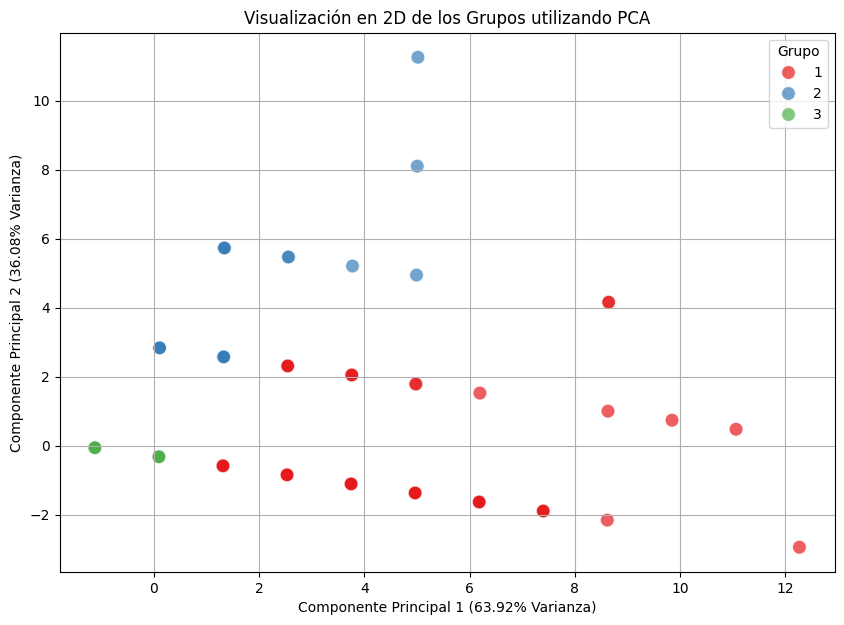

Varianza explicada total: 100.00%


In [7]:
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Aplicar PCA para reducir las 3 dimensiones a 2D
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_sample)

# Crear un DataFrame con las coordenadas de PCA y la etiqueta del grupo
df_pca = pd.DataFrame(X_pca, columns=['Componente 1', 'Componente 2'])
df_pca['Grupo'] = df_sample['Grupo'].values

# Obtener el porcentaje de varianza explicada
var_explicada = pca.explained_variance_ratio_ * 100

# Graficar el resultado
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x='Componente 1',
    y='Componente 2',
    hue='Grupo',
    palette='Set1',
    data=df_pca,
    alpha=0.7,
    s=100
)

plt.title('Visualización en 2D de los Grupos utilizando PCA')
plt.xlabel(f'Componente Principal 1 ({var_explicada[0]:.2f}% Varianza)')
plt.ylabel(f'Componente Principal 2 ({var_explicada[1]:.2f}% Varianza)')
plt.grid(True)
plt.legend(title='Grupo')
plt.show()

print(f"Varianza explicada total: {sum(var_explicada):.2f}%")

---
## <font color='264CC7'> Métricas  </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
Calcula la métrica de la silueta para los grupos obtenidos. ¿Qué tan buenos te parecen los grupos?
</div>

In [8]:
# Calcular el coeficiente de silueta para evaluar la calidad de los grupos
sil_score = silhouette_score(X_sample, grupos)
print(f"Coeficiente de Silueta para 3 clusters (Ward): {sil_score:.4f}")

Coeficiente de Silueta para 3 clusters (Ward): 0.7132


---
## <font color='264CC7'> Iteraciones </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Realiza el proceso de agrupamiento jerárquico con diferentes parámetros, analiza la métrica de la silueta de cada uno e indica cuál es el mejor.
</div>

import pandas as pd
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import silhouette_score

# Definir los parámetros de prueba
metodos = ['ward', 'complete', 'average', 'single']
metricas = ['euclidean', 'cityblock']

resultados = []

for metodo in metodos:
    for metrica in metricas:
        # El método Ward requiere obligatoriamente distancia euclídea en scipy
        if metodo == 'ward' and metrica != 'euclidean':
            continue
            
        try:
            # Calcular el enlace
            Z_iter = linkage(X_sample, method=metodo, metric=metrica)
            # Obtener 3 clusters
            etiquetas = fcluster(Z_iter, t=3, criterion='maxclust')
            
            # Calcular la silueta
            sil_score_iter = silhouette_score(X_sample, etiquetas)
            
            resultados.append({
                'Método de Enlace': metodo,
                'Métrica de Distancia': metrica,
                'Coeficiente de Silueta': sil_score_iter
            })
        except Exception as e:
            # Capturar errores si alguna métrica no es compatible con el método
            continue

# Convertir y mostrar los resultados
df_resultados = pd.DataFrame(resultados).sort_values(by='Coeficiente de Silueta', ascending=False)
print("--- Resultados de Iteraciones con Diferentes Parámetros ---")
display(df_resultados)

# Indicar el mejor modelo
mejor_config = df_resultados.iloc[0]
print(f"\nLa mejor configuración es:\nMétodo: {mejor_config['Método de Enlace']}\nMétrica: {mejor_config['Métrica de Distancia']}\nSilueta: {mejor_config['Coeficiente de Silueta']:.4f}")